# Kiểm chứng EHO theo Chương 12

Ở mục 12.5, sách cho sẵn vị trí và điểm số của năm cá thể. Notebook tính lại các giá trị đó bằng mã Python của dự án. Cột `delta` là kết quả Python trừ kết quả in trong sách. Vì sách làm tròn số, bảng dùng `tolerance` để cho biết sai khác tối đa được chấp nhận.

In [1]:
import pandas as pd
from IPython.display import display
from objectives.book_replay import verify_book_example

data, best, worst, rows = verify_book_example()
table = pd.DataFrame(rows)
display(pd.DataFrame(data["initial_population"], index=range(1, 6)))
display(table.iloc[:5])
print(f"Best x{best + 1}; Worst x{worst + 1}; alpha={data['alpha']}; beta={data['beta']}")

,0,1,2,3
1,-2.542,-2.146,1.199,-2.403
2,3.322,4.943,2.358,-1.599
3,0.870,-4.016,4.161,3.888
4,3.254,-2.450,0.966,-4.890
5,-0.765,-1.918,-3.466,-3.290


,step,book,python,delta,tolerance,status
0,Fitness ban đầu [1],66.903,66.903259,0.000259,0.001,MATCH
1,Fitness ban đầu [2],92.995,92.995412,0.000412,0.001,MATCH
2,Fitness ban đầu [3],59.591,59.591103,0.000103,0.001,MATCH
3,Fitness ban đầu [4],73.720,73.720324,0.000324,0.001,MATCH
4,Fitness ban đầu [5],69.718,69.717864,-0.000136,0.001,MATCH


Best x3; Worst x2; alpha=0.5; beta=0.1


## Tâm và ba toán tử

Tâm của quần thể được tính bằng cách lấy trung bình từng tọa độ ở các vị trí cũ (12.3). Cá thể 1 tiến về nghiệm tốt nhất bằng các số r mà sách cho sẵn (12.1). Cá thể 3 là đầu đàn nên vị trí mới bằng beta nhân với tâm cũ (12.2). Cá thể 2 được đặt ở vị trí mới bằng công thức (12.4), có giữ số +1.

In [2]:
print("r của x1:", data["regular_random"])
print("r của x2:", data["separation_random"])
display(table.iloc[5:21])
display(pd.DataFrame(data["updated_population"], index=range(1, 6)))

r của x1: [0.671, 0.459, 0.036, 0.901]
r của x2: [0.706, 0.032, 0.277, 0.046]


,step,book,python,delta,tolerance,status
5,Tâm [1],0.828,0.827800,-0.000200,0.00051,MATCH
6,Tâm [2],-1.117,-1.117400,-0.000400,0.00051,MATCH
7,Tâm [3],1.044,1.043600,-0.000400,0.00051,MATCH
8,Tâm [4],-1.659,-1.658800,0.000200,0.00051,MATCH
9,x1 (12.1) [1],-1.397,-1.397274,-0.000274,0.00051,MATCH
10,x1 (12.1) [2],-2.575,-2.575165,-0.000165,0.00051,MATCH
11,x1 (12.1) [3],1.252,1.252316,0.000316,0.00051,MATCH
12,x1 (12.1) [4],0.431,0.431096,0.000096,0.00051,MATCH
13,x2 (12.4) [1],2.815,2.815440,0.000440,0.00051,MATCH
14,x2 (12.4) [2],-4.760,-4.760320,-0.000320,0.00051,MATCH


,0,1,2,3
1,-1.397,-2.575,1.252,0.431
2,2.815,-4.760,-2.007,-4.603
3,0.083,-0.112,0.104,-0.166
4,2.242,-3.181,2.050,-1.564
5,-0.158,-2.330,-0.966,-2.676


## Fitness mới và kết luận

Bảng cuối tính lại fitness, tức điểm của từng nghiệm, từ các tọa độ mới đã in trong sách. Sách cho tọa độ mới của x4 và x5 nhưng thiếu các số ngẫu nhiên r đã dùng. Vì thế, ta kiểm tra được điểm của hai cá thể này từ tọa độ đã in. Để tự tính lại cả bước di chuyển, ta vẫn cần các số r còn thiếu. Biểu đồ cột cho thấy sai khác tuyệt đối của từng phép so sánh.

,step,book,python,delta,tolerance,status
21,Fitness từ tọa độ in [1],76.424,76.424013,0.000013,0.001,MATCH
22,Fitness từ tọa độ in [2],89.186,89.185714,-0.000286,0.001,MATCH
23,Fitness từ tọa độ in [3],10.787,10.786537,-0.000463,0.001,MATCH
24,Fitness từ tọa độ in [4],56.782,56.782374,0.000374,0.001,MATCH
25,Fitness từ tọa độ in [5],47.613,47.612740,-0.000260,0.001,MATCH


26/26 giá trị nằm trong dung sai.


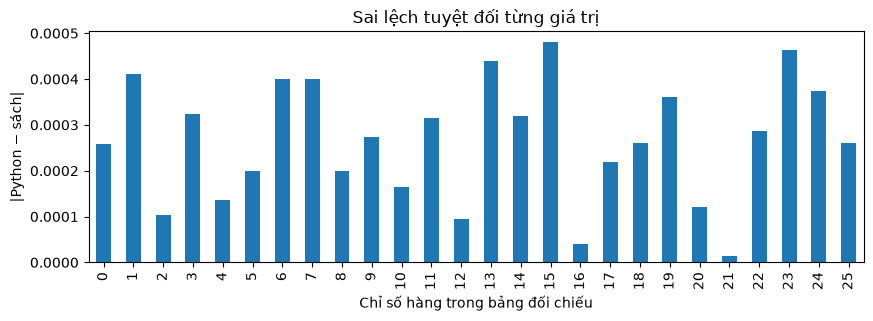

In [3]:
display(table.iloc[21:])
assert rows == verify_book_example()[3]
assert (best, worst) == (2, 1)
print(f"{sum(table.status == 'MATCH')}/{len(table)} giá trị nằm trong dung sai.")
ax = table["delta"].abs().plot.bar(figsize=(10, 3), title="Sai lệch tuyệt đối từng giá trị")
ax.set(xlabel="Chỉ số hàng trong bảng đối chiếu", ylabel="|Python − sách|");